In [1]:
import os
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "nn").exists() else Path.cwd().parent
os.chdir(ROOT)

In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from nn import *
from nn.data import load_image_folder, one_hot
from nn.visualizations import plot_history, plot_digits, plot_confusion_matrix

In [3]:
os.getcwd()

'/Users/arjunadhithyarr/Documents/z-arjun/numpy-neural-net-play'

In [4]:
data_dir = Path("data/mnist_images")

X_train, y_train = load_image_folder(data_dir / "train")
X_test, y_test = load_image_folder(data_dir / "test")

print("train", X_train.shape, "  test", X_test.shape, "  pixels", X_train.min(), "to", X_train.max())
print("train images per digit", np.bincount(y_train, minlength=10))
print("test images per digit ", np.bincount(y_test, minlength=10))

train (50, 784)   test (50, 784)   pixels 0.0 to 1.0
train images per digit [4 7 4 7 4 4 5 4 4 7]
test images per digit  [5 9 5 4 9 4 3 6 0 5]


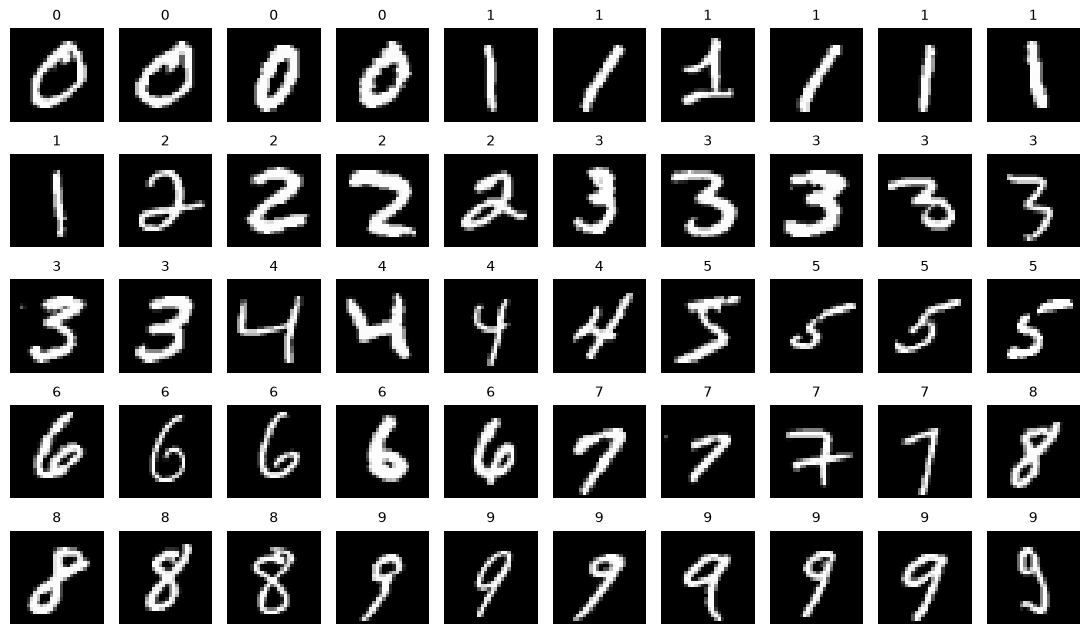

In [5]:
plot_digits(X_train, y_train)

In [6]:
Y_train = one_hot(y_train, 10)
Y_test = one_hot(y_test, 10)

print("one image  ", X_train[0].shape)
print("label      ", y_train[0])
print("one-hot    ", Y_train[0])

one image   (784,)
label       0
one-hot     [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [7]:
input_layer = 784
layer1 = 128
layer1_activation = relu
layer2 = 64
layer2_activation = relu
output_layer = 10
# softmax is applied inside softmax_cross_entropy, so the output layer itself stays linear
output_activation = linear

In [8]:
rng = np.random.default_rng(0)

def scaled_W(n, n_inputs):
    # 1/sqrt(n_inputs): a neuron summing n_inputs pixels stays near z ~ 0
    return rng.normal(0, 1 / np.sqrt(n_inputs), (n, n_inputs))

hidden1 = multipleNeuron(
    n=layer1, n_inputs=input_layer, activation=layer1_activation,
    W=scaled_W(layer1, input_layer), b=np.zeros(layer1),
)
hidden2 = multipleNeuron(
    n=layer2, n_inputs=layer1, activation=layer2_activation,
    W=scaled_W(layer2, layer1), b=np.zeros(layer2),
)
output = multipleNeuron(
    n=output_layer, n_inputs=layer2, activation=output_activation,
    W=scaled_W(output_layer, layer2), b=np.zeros(output_layer),
)

net = stackLayers([hidden1, hidden2, output])
net

stackLayers(784 -> 128 relu -> 64 relu -> 10 linear)

## Softmax

The output layer gives 10 raw scores (logits). Softmax turns them into probabilities that are all positive and add up to 1:

$$p_k = \frac{e^{z_k}}{\sum_j e^{z_j}}$$

The loss is $-\log p_{\text{true digit}}$: near 0 when the network is confident and right, large when it is confident and wrong. Its gradient with respect to the logits is just `softmax(z) - target`, which is what `softmax_cross_entropy_derivative` hands to `net.backward`.

The weights are drawn with standard deviation `1 / sqrt(n_inputs)`, the same scale as the tanh MNIST notebook. `multipleNeuron`'s default is standard normal. With 784 inputs that default puts the logits in the hundreds, softmax outputs exactly 0 or 1, and `softmax(z) - target` is zero, so the weights never move.

In [9]:
loss_fn = softmax_cross_entropy

logits = net.forward(X_train[0])
probs = softmax(logits)

print("logits  ", np.round(logits, 1))
print("softmax ", np.round(probs, 3), "  sum", round(float(probs.sum()), 6))
print("true digit", y_train[0], "  predicted", probs.argmax(), f"  loss {loss_fn(Y_train[0], logits):.2f}")

logits   [ 0.2 -0.2  0.  -0.  -0.4 -0.2 -0.   0.2 -0.1  0. ]
softmax  [0.133 0.087 0.109 0.101 0.068 0.084 0.099 0.121 0.092 0.107]   sum 1.0
true digit 0   predicted 0   loss 2.02


## One step by hand, then train

`lr` is `0.05`. The scaled weights keep the first logits near zero, so this step moves the loss. `0.1` is still large enough that most ReLU units get pushed to `z < 0` and stay dead.

In [10]:
lr = 0.05
x0, t0 = X_train[0], Y_train[0]

logits = net.forward(x0)
loss_before = loss_fn(t0, logits)

net.backward(softmax_cross_entropy_derivative(t0, logits))
sgd_step(net, lr)

loss_after = loss_fn(t0, net.forward(x0))
print(f"loss on this image {loss_before:.2f} -> {loss_after:.2f}")

loss on this image 2.02 -> 0.98


In [11]:
history = train(net, X_train, Y_train, loss_fn, lr=lr, epochs=1000,
                X_val=X_test, Y_val=Y_test, log_every=50, seed=0)

epoch    1  loss 1.7247  acc 0.520  val_loss 2.0971  val_acc 0.280


epoch   50  loss 0.0007  acc 1.000  val_loss 0.9670  val_acc 0.660


epoch  100  loss 0.0003  acc 1.000  val_loss 0.9930  val_acc 0.700


epoch  150  loss 0.0002  acc 1.000  val_loss 1.0092  val_acc 0.700


epoch  200  loss 0.0001  acc 1.000  val_loss 1.0209  val_acc 0.700


epoch  250  loss 0.0001  acc 1.000  val_loss 1.0305  val_acc 0.700


... (11 outputs left out)

epoch  850  loss 0.0000  acc 1.000  val_loss 1.0863  val_acc 0.700


epoch  900  loss 0.0000  acc 1.000  val_loss 1.0891  val_acc 0.700


epoch  950  loss 0.0000  acc 1.000  val_loss 1.0917  val_acc 0.700


epoch 1000  loss 0.0000  acc 1.000  val_loss 1.0942  val_acc 0.700


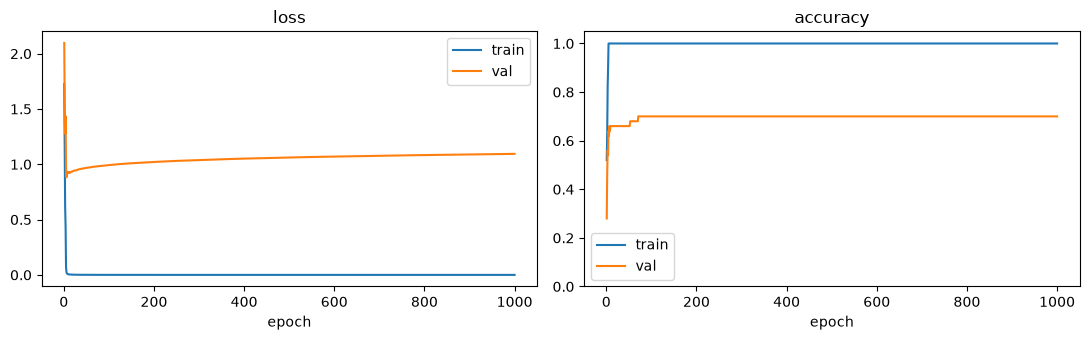

In [12]:
plot_history(history)

## Results

With the scaled start, test accuracy leaves the chance level (about 0.10), reaches 0.70 by epoch 100, and stays there. Training accuracy is 1.0: fifty images is enough to memorize, and the test set is small and uneven, so 0.70 is as far as this run generalizes.

Green is correct. Red shows the prediction, with the true digit in brackets.

train accuracy 1.00  (50/50)
test accuracy  0.70  (35/50)
mean confidence on test  0.82


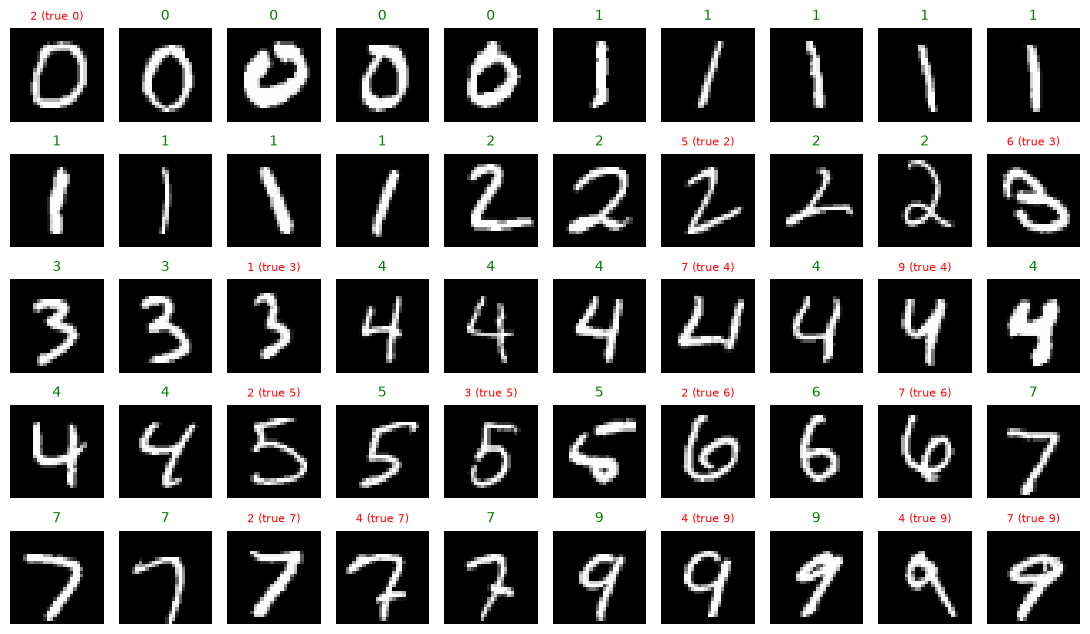

In [13]:
train_pred = predict(net, X_train).argmax(axis=1)
test_probs = softmax(predict(net, X_test))
test_pred = test_probs.argmax(axis=1)

print(f"train accuracy {np.mean(train_pred == y_train):.2f}  ({np.sum(train_pred == y_train)}/{len(y_train)})")
print(f"test accuracy  {np.mean(test_pred == y_test):.2f}  ({np.sum(test_pred == y_test)}/{len(y_test)})")
print(f"mean confidence on test  {test_probs.max(axis=1).mean():.2f}")

plot_digits(X_test, y_test, test_pred)

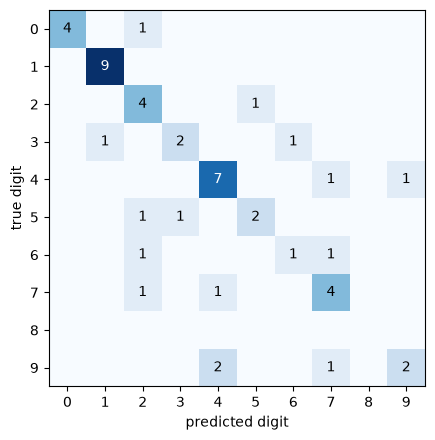

In [14]:
plot_confusion_matrix(y_test, test_pred)

## Save and reload a checkpoint

In [15]:
ckpt_path = save_checkpoint(
    net, "checkpoints/mnist_784-128-64-10_softmax",
    epoch=history["epoch"][-1], lr=lr,
    train_accuracy=history["accuracy"][-1], test_accuracy=history["val_accuracy"][-1],
    history=history,
)
restored, meta = load_checkpoint(ckpt_path)

print(ckpt_path)
print(restored, "  epoch", meta["epoch"], "  test acc", meta["test_accuracy"])
print("same predictions:", np.allclose(predict(net, X_test), predict(restored, X_test)))

checkpoints/mnist_784-128-64-10_softmax.npz
stackLayers(784 -> 128 relu -> 64 relu -> 10 linear)   epoch 1000   test acc 0.7
same predictions: True
